In [1]:
import sys
sys.path.insert(0, "..") # add parent CNODE package to sys.path

import numpy as np
import matplotlib.pyplot as plt
from data.vdpo.vdpo_loader import create_vdpo_dataset
from src.models.node_pyomo_base import NODEPyomo

## 1. Create dataset of VDPO state vectors

Full grid shape: (399,)
Train grid shape: (200,)
Test grid shape: (200,)
Y_true shape: (399, 2)
Y_obs shape: (200, 2)
Y_obs displacement average value: 0.11
Y_obs velocity average value: 0.52
Y_obs displacement range: [-2.59, 2.46]
Y_obs velocity range: [-3.86, 3.93]


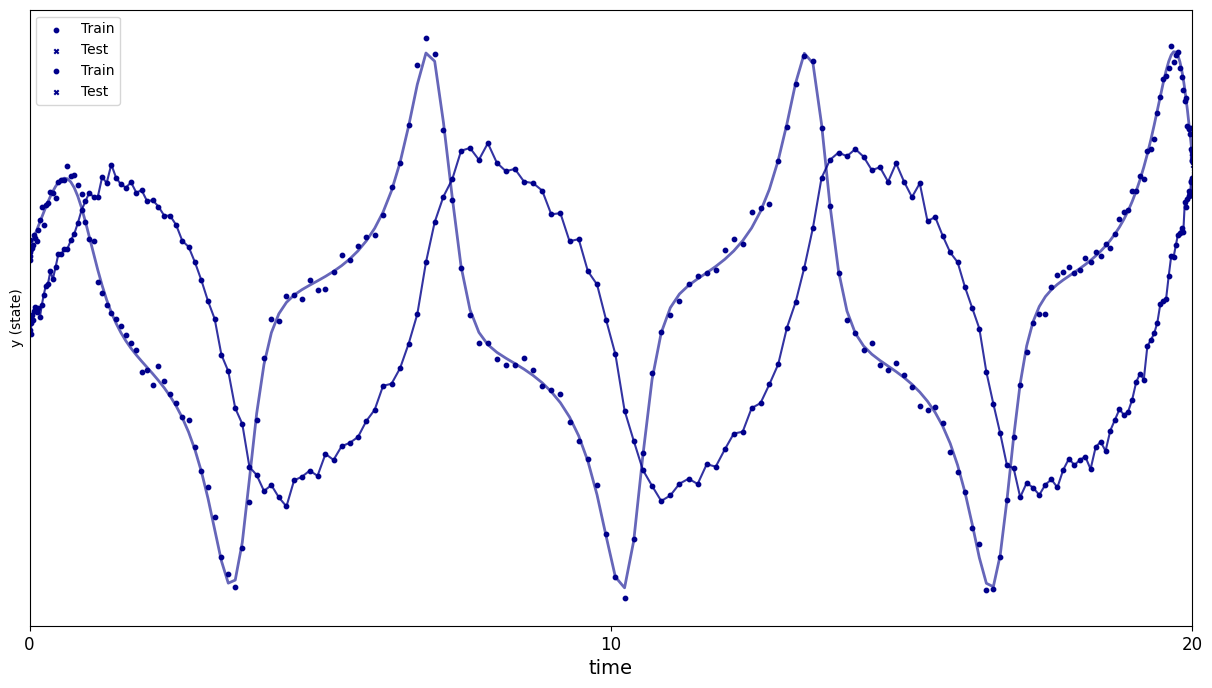

In [2]:
train_interpol, train_grid, Y_obs, test_interpol, test_grid, Y_test, full_grid, Y_true, Y_smooth = create_vdpo_dataset(num_nodes=400, end_time=40, noise_sd=0.1)

# Print dataset shapes and summary stats 
print(f"Full grid shape: {full_grid.shape}")
print(f"Train grid shape: {train_grid.shape}")
print(f"Test grid shape: {test_grid.shape}")
print(f"Y_true shape: {Y_true.shape}")
print(f"Y_obs shape: {Y_obs.shape}")
print(f"Y_obs displacement average value: {np.mean(Y_obs[:, 0]):.2f}")
print(f"Y_obs velocity average value: {np.mean(Y_obs[:, 1]):.2f}")
print(f"Y_obs displacement range: [{Y_obs[:, 0].min():.2f}, {Y_obs[:, 0].max():.2f}]")
print(f"Y_obs velocity range: [{Y_obs[:, 1].min():.2f}, {Y_obs[:, 1].max():.2f}]")

# Visualise trajectories from train and test datasets 
plt.figure(figsize=(15, 8))

dc_color = (160/255, 190/255, 200/255)
irrdc_color = (245/255, 150/255, 150/255)

# Jagged interpolation through observed noisy data
plt.plot(train_grid, Y_obs[:, 0], color='darkblue', linewidth=1.5, alpha=0.8)
plt.xticks([])
plt.yticks([])
plt.plot(full_grid, Y_true[:, 1], color='darkblue', linewidth=2, alpha=0.6)

# Noisy observed data points showing variance
plt.scatter(train_grid, Y_obs[:, 0], color='darkblue', marker='o', s=10, label="Train")
plt.scatter(test_grid, Y_test[:, 0], color='darkblue', marker='x', s=10, label="Test")
plt.scatter(train_grid, Y_obs[:, 1], color='darkblue', marker='o', s=10, label="Train")
plt.scatter(test_grid, Y_test[:, 1], color='darkblue', marker='x', s=10, label="Test")
plt.xlabel('time', size=14)
plt.ylabel('y (state)')
plt.xticks(np.arange(0, full_grid[-1] + 1e-9, 10), size=12)
plt.xlim(full_grid[0], train_grid[-1])
plt.legend()

## 2. Train the Neural ODE 

### Solve Pyomo model with DC method

In [3]:
T = train_grid[-1] - train_grid[0]
layer_sizes = [2, 32, 2] 

solver_options_dc = {
    "max_iter": 500,
    "nlp_scaling_method": "gradient-based",
    "mu_strategy": "adaptive",
    "tol": 1e-8,
    "acceptable_tol": 1e-7,
    "acceptable_iter": 10
}

pyo_model_dc = NODEPyomo(
    Y_obs, layer_sizes, T, 
    state_lower_bound=-5,
    state_upper_bound=35,
    param_lower_bound=-50,
    param_upper_bound=50,
    lambda_reg=1e-4, 
    Y_smooth=Y_smooth, 
    transcription_method='dc'
)
pyo_model_dc.solve_model(solver_options_dc)

Ipopt 3.14.19: max_iter=500
nlp_scaling_method=gradient-based
mu_strategy=adaptive
tol=1e-08
acceptable_tol=1e-07
acceptable_iter=10
option_file_name=/Users/bms125/Desktop/Projects/PhD/CNODE/ipopt.opt

Using option file "/Users/bms125/Desktop/Projects/PhD/CNODE/ipopt.opt".


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.19, running with linear solver ma57.

Number of nonzeros in equality constraint Jacobian...:   131342
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:    64729

Total number of variables............................:      562
                

ApplicationError: Solver (ipopt) did not exit normally

### Solve Pyomo model with IRR-DC method

In [25]:
solver_options_irrdc = {
    "max_iter": 1000,
    "nlp_scaling_method": "gradient-based",
    "mu_strategy": "adaptive",
    "tol": 1e-6,
    "acceptable_tol": 1e-5,
    "acceptable_iter": 10
} 

pyo_model_irrdc = NODEPyomo(
    Y_obs, layer_sizes, T, 
    state_lower_bound=-5,
    state_upper_bound=35,
    param_lower_bound=-50,
    param_upper_bound=50,
    lambda_reg=1e-4, 
    Y_smooth=Y_smooth, 
    transcription_method='irrdc',
    rho_reg=1,
    num_res_eval_nodes=250
)
pyo_model_irrdc.solve_model(solver_options_irrdc)

Number of node clashes between res eval grid and colloc grid: 3 of 250 res eval nodes.
Ipopt 3.14.19: max_iter=1000
nlp_scaling_method=gradient-based
mu_strategy=adaptive
tol=1e-06
acceptable_tol=1e-05
acceptable_iter=10
option_file_name=/Users/bms125/Desktop/Projects/PhD/CNODE/ipopt.opt

Using option file "/Users/bms125/Desktop/Projects/PhD/CNODE/ipopt.opt".


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

Solution is feasible and optimal
NN parameters have been frozen


In [26]:
'''# Sweep IRR-DC across rho_reg magnitudes
rho_reg_sweep = np.logspace(-3, 1, 5)
pyo_model_irrdc_sweep = {}

for rho in rho_reg_sweep:
    pyo_model = NODEPyomo(
        Y_obs, layer_sizes, T,
        state_lower_bound=-5,
        state_upper_bound=50,
        param_lower_bound=-100,
        param_upper_bound=100,
        lambda_reg=1e-3,
        Y_smooth=Y_smooth,
        transcription_method='irrdc',
        rho_reg=float(rho),
        num_res_eval_nodes=200
    )
    pyo_model.solve_model(solver_options_irrdc)
    pyo_model_irrdc_sweep[float(rho)] = pyo_model'''

"# Sweep IRR-DC across rho_reg magnitudes\nrho_reg_sweep = np.logspace(-3, 1, 5)\npyo_model_irrdc_sweep = {}\n\nfor rho in rho_reg_sweep:\n    pyo_model = NODEPyomo(\n        Y_obs, layer_sizes, T,\n        state_lower_bound=-5,\n        state_upper_bound=50,\n        param_lower_bound=-100,\n        param_upper_bound=100,\n        lambda_reg=1e-3,\n        Y_smooth=Y_smooth,\n        transcription_method='irrdc',\n        rho_reg=float(rho),\n        num_res_eval_nodes=200\n    )\n    pyo_model.solve_model(solver_options_irrdc)\n    pyo_model_irrdc_sweep[float(rho)] = pyo_model"

### Train Neural ODE using sequential method

In [27]:
'''from src.models.node_torch_base import NODESequential

# Sequential (solver-in-the-loop) training options. Solver/optimiser defaults follow
# Appendix A.2 (dopri5, rtol=1e-3, atol=1e-6, Adam lr=1e-3). Set pretrain_iterations > 0
# to enable supervised derivative pre-training (Section 5.2) before end-to-end training.
seq_options = {
    "num_iterations": 50000,
    "learning_rate": 1e-3,
    "pretrain_iterations": 0,
    "pretrain_fraction": 0.2,
}

node_seq = NODESequential(
    Y_obs, train_grid, layer_sizes,
    lambda_reg=1e-3,
    solver_method="dopri5",
    rtol=1e-3,
    atol=1e-6,
)
seq_history = node_seq.train(
    num_iterations=seq_options["num_iterations"],
    learning_rate=seq_options["learning_rate"],
    pretrain_iterations=seq_options["pretrain_iterations"],
    pretrain_fraction=seq_options["pretrain_fraction"],
    verbose=True,
    log_every=100
)'''

'from src.models.node_torch_base import NODESequential\n\n# Sequential (solver-in-the-loop) training options. Solver/optimiser defaults follow\n# Appendix A.2 (dopri5, rtol=1e-3, atol=1e-6, Adam lr=1e-3). Set pretrain_iterations > 0\n# to enable supervised derivative pre-training (Section 5.2) before end-to-end training.\nseq_options = {\n    "num_iterations": 50000,\n    "learning_rate": 1e-3,\n    "pretrain_iterations": 0,\n    "pretrain_fraction": 0.2,\n}\n\nnode_seq = NODESequential(\n    Y_obs, train_grid, layer_sizes,\n    lambda_reg=1e-3,\n    solver_method="dopri5",\n    rtol=1e-3,\n    atol=1e-6,\n)\nseq_history = node_seq.train(\n    num_iterations=seq_options["num_iterations"],\n    learning_rate=seq_options["learning_rate"],\n    pretrain_iterations=seq_options["pretrain_iterations"],\n    pretrain_fraction=seq_options["pretrain_fraction"],\n    verbose=True,\n    log_every=100\n)'

## 3. Use the trained model as RHS of an ODE system 

In [28]:
y0_train = Y_obs[0, :]
y0_test = Y_test[0, :]

train_eval_grid = np.linspace(0, 20, 1000)
test_eval_grid = np.linspace(20, 40, 1000)

predicted_trajectory_train_irrdc = pyo_model_irrdc.get_predicted_trajectory(y0_train, train_eval_grid, rtol=1e-7, atol=1e-9, max_step=(train_eval_grid[1]-train_eval_grid[0]))
predicted_trajectory_test_irrdc = pyo_model_irrdc.get_predicted_trajectory(y0_test, test_eval_grid, rtol=1e-7, atol=1e-9, max_step=(test_eval_grid[1]-test_eval_grid[0]))

predicted_trajectory_train_dc = pyo_model_dc.get_predicted_trajectory(y0_train, train_eval_grid, rtol=1e-7, atol=1e-9, max_step=(train_eval_grid[1]-train_eval_grid[0]))
predicted_trajectory_test_dc = pyo_model_dc.get_predicted_trajectory(y0_test, test_eval_grid, rtol=1e-7, atol=1e-9, max_step=(test_eval_grid[1]-test_eval_grid[0]))

'''predicted_trajectory_train_seq = node_seq.get_predicted_trajectory(y0_train, train_eval_grid, rtol=1e-7, atol=1e-9, max_step=(train_eval_grid[1]-train_eval_grid[0]))
predicted_trajectory_test_seq = node_seq.get_predicted_trajectory(y0_test, test_eval_grid, rtol=1e-7, atol=1e-9, max_step=(test_eval_grid[1]-test_eval_grid[0]))'''

'predicted_trajectory_train_seq = node_seq.get_predicted_trajectory(y0_train, train_eval_grid, rtol=1e-7, atol=1e-9, max_step=(train_eval_grid[1]-train_eval_grid[0]))\npredicted_trajectory_test_seq = node_seq.get_predicted_trajectory(y0_test, test_eval_grid, rtol=1e-7, atol=1e-9, max_step=(test_eval_grid[1]-test_eval_grid[0]))'

## 4. Plot predicted trajectories over train and test domains

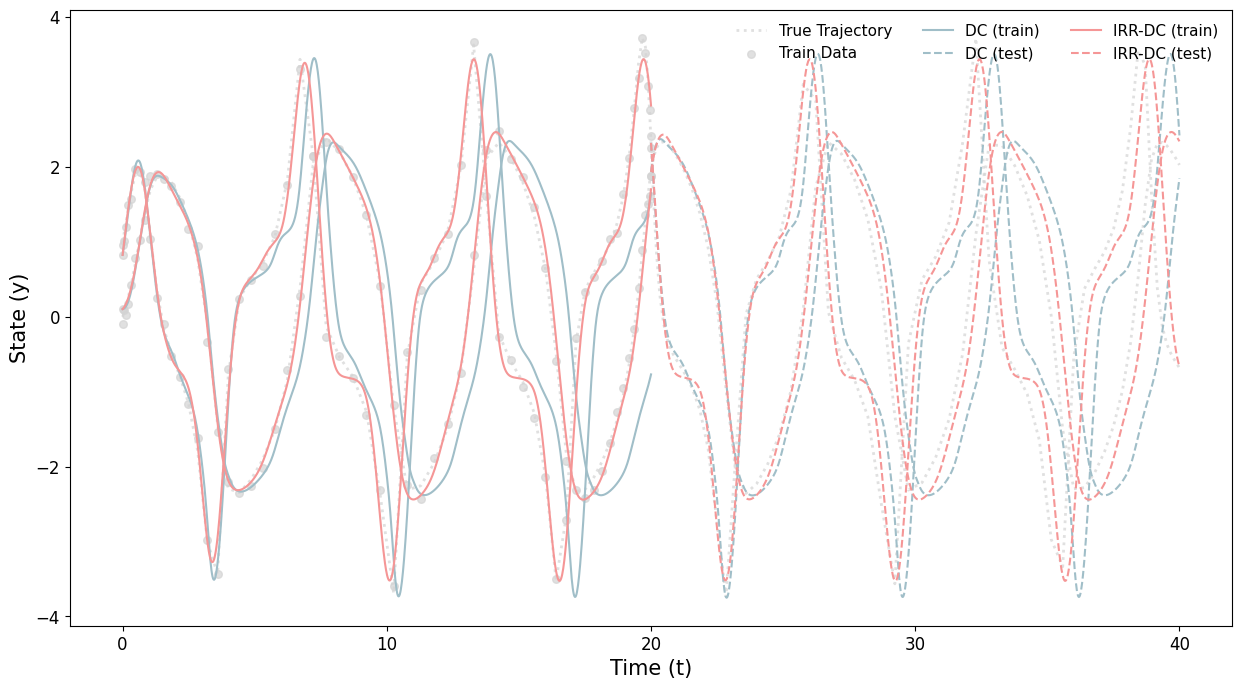

In [29]:
# ---- Overlay: DC vs IRR-DC vs Sequential, train + test predicted trajectories ----
# Reuses the predictions computed in the cell above (on train_eval_grid / test_eval_grid).
method_colors = {'dc': dc_color, 'irrdc': irrdc_color, 'seq': (150/255, 200/255, 150/255)}
method_labels = {'dc': 'DC', 'irrdc': 'IRR-DC', 'seq': 'Sequential'}

pred_train = {
    'dc':    predicted_trajectory_train_dc,
    'irrdc': predicted_trajectory_train_irrdc,
    #'seq':   predicted_trajectory_train_seq,
}
pred_test = {
    'dc':    predicted_trajectory_test_dc,
    'irrdc': predicted_trajectory_test_irrdc,
    #'seq':   predicted_trajectory_test_seq,
}

plt.figure(figsize=(15, 8))

# True trajectory (both states), dotted
plt.plot(full_grid, Y_true[:, 0], color='lightgrey', linestyle=':', linewidth=2, alpha=0.7, label="True Trajectory")
plt.plot(full_grid, Y_true[:, 1], color='lightgrey', linestyle=':', linewidth=2, alpha=0.7)

# Training data (both states)
plt.scatter(train_grid, Y_obs[:, 0], color='lightgrey', marker='o', s=30, alpha=0.7, label="Train Data")
plt.scatter(train_grid, Y_obs[:, 1], color='lightgrey', marker='o', s=30, alpha=0.7)

# Predicted trajectories: train solid, test dashed; both states share the method colour
for method in ('dc', 'irrdc'): #, 'seq'):
    c = method_colors[method]
    tr, te = pred_train[method], pred_test[method]
    plt.plot(train_eval_grid, tr[:, 0], color=c, label=f"{method_labels[method]} (train)")
    plt.plot(train_eval_grid, tr[:, 1], color=c)
    plt.plot(test_eval_grid, te[:, 0], color=c, linestyle='--', label=f"{method_labels[method]} (test)")
    plt.plot(test_eval_grid, te[:, 1], color=c, linestyle='--')

plt.xlabel('Time (t)', fontsize=15)
plt.ylabel('State (y)', fontsize=15)
plt.yticks([-4, -2, 0, 2, 4], fontsize=12)
plt.xticks([0, 10, 20, 30, 40], fontsize=12)
plt.legend(loc='upper right', ncol=3, frameon=False, fontsize=11)

## 5. Plot ODE residual in training domain

Number of node clashes between res eval grid and colloc grid: 2 of 5000 res eval nodes.
Number of node clashes between res eval grid and colloc grid: 2 of 5000 res eval nodes.


Text(0.5, 0.98, '$\\mathbf{r}(t) = \\dot{\\mathbf{Y}}(t) - \\mathbf{F}_{\\boldsymbol{\\theta}}(\\mathbf{Y}(t))$')

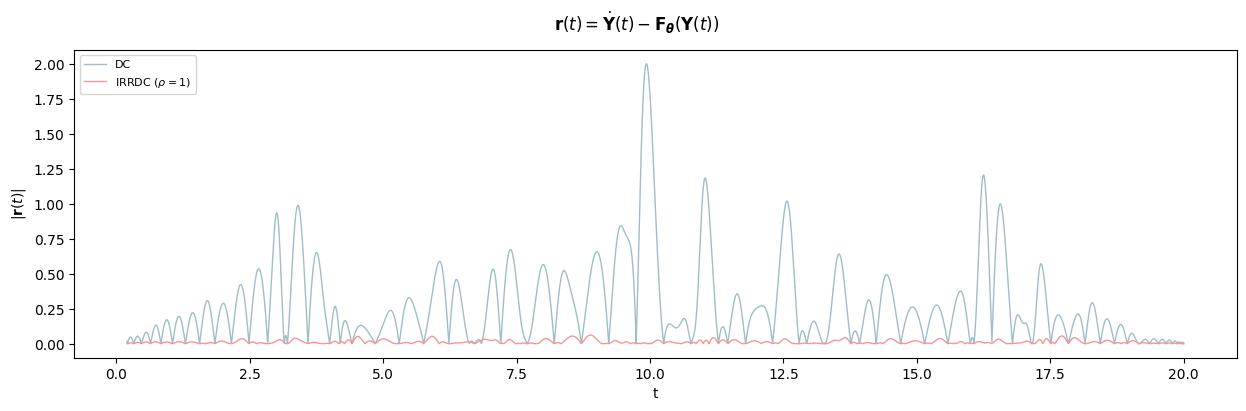

In [30]:
from src.models.direct_collocation import BarycentricInterpolation

def compute_continuous_residual(pyo_model, num_eval_nodes):
    """
    Compute r(t) = dY*/dt - F_θ(Y*(t)) on a dense equidistant grid by
    barycentric interpolation of the trained collocation solution.
    Works for both 'dc' and 'irrdc' models.
    Returns: t_eval (num_eval_nodes,), residual (num_eval_nodes, state_dim)
    """
    N = pyo_model.num_colloc_nodes
    bary = BarycentricInterpolation(
        0, pyo_model.end_time, N,
        transcription_method='irrdc',
        num_res_eval_nodes=num_eval_nodes
    )
    L = bary.L_res # (num_eval_nodes, N)
    D = bary.D_res # (num_eval_nodes, N)
    t_eval = bary.res_eval_grid.astype(float)

    Y_star = pyo_model.pyomo_var_to_numpy(pyo_model.model.Y_star, (N, pyo_model.state_dim))
    Ws = pyo_model.convert_weights()
    bs = pyo_model.convert_biases()

    ode_lhs = D @ Y_star
    Y_eval  = L @ Y_star
    nn_out  = np.array([pyo_model.nn_prediction(0, Y_eval[i], Ws, bs) for i in range(num_eval_nodes)])

    return t_eval, ode_lhs - nn_out


#-----------------------------------PLOTTING CODE--------------------------------------
num_eval_nodes = 5000

t_cont_dc, res_train_dc = compute_continuous_residual(pyo_model_dc, num_eval_nodes)
t_cont_irrdc, res_train_irrdc = compute_continuous_residual(pyo_model_irrdc, num_eval_nodes)

skip_plot_points = 50
t_plot_dc     = t_cont_dc[skip_plot_points:]     if len(t_cont_dc)    > skip_plot_points else t_cont_dc
res_plot_dc   = res_train_dc[skip_plot_points:]  if len(res_train_dc) > skip_plot_points else res_train_dc
t_plot_irrdc  = t_cont_irrdc[skip_plot_points:]  if len(t_cont_irrdc) > skip_plot_points else t_cont_irrdc
res_plot_irrdc = res_train_irrdc[skip_plot_points:] if len(res_train_irrdc) > skip_plot_points else res_train_irrdc

state_idx = 1  # velocity state variable only
y_label = r'$|\mathbf{r}(t)|$'

fig, ax = plt.subplots(figsize=(15, 4))

ax.plot(t_plot_dc,    np.abs(res_plot_dc[:, state_idx]),    color=dc_color, linewidth=1.0,
        label='DC')
ax.plot(t_plot_irrdc, np.abs(res_plot_irrdc[:, state_idx]), color=irrdc_color, linewidth=1.0,
        label=r'IRRDC ($\rho=$' + f'{pyo_model_irrdc.rho_reg})')

#ax.set_title('Velocity')
ax.set_xlabel('t')
ax.set_ylabel(y_label)
ax.legend(loc='upper left', fontsize=8)

fig.suptitle(r'$\mathbf{r}(t) = \dot{\mathbf{Y}}(t) - \mathbf{F}_{\boldsymbol{\theta}}(\mathbf{Y}(t))$')


## 6. Combined plot: predicted velocity trajectory (top) over ODE residual (bottom)


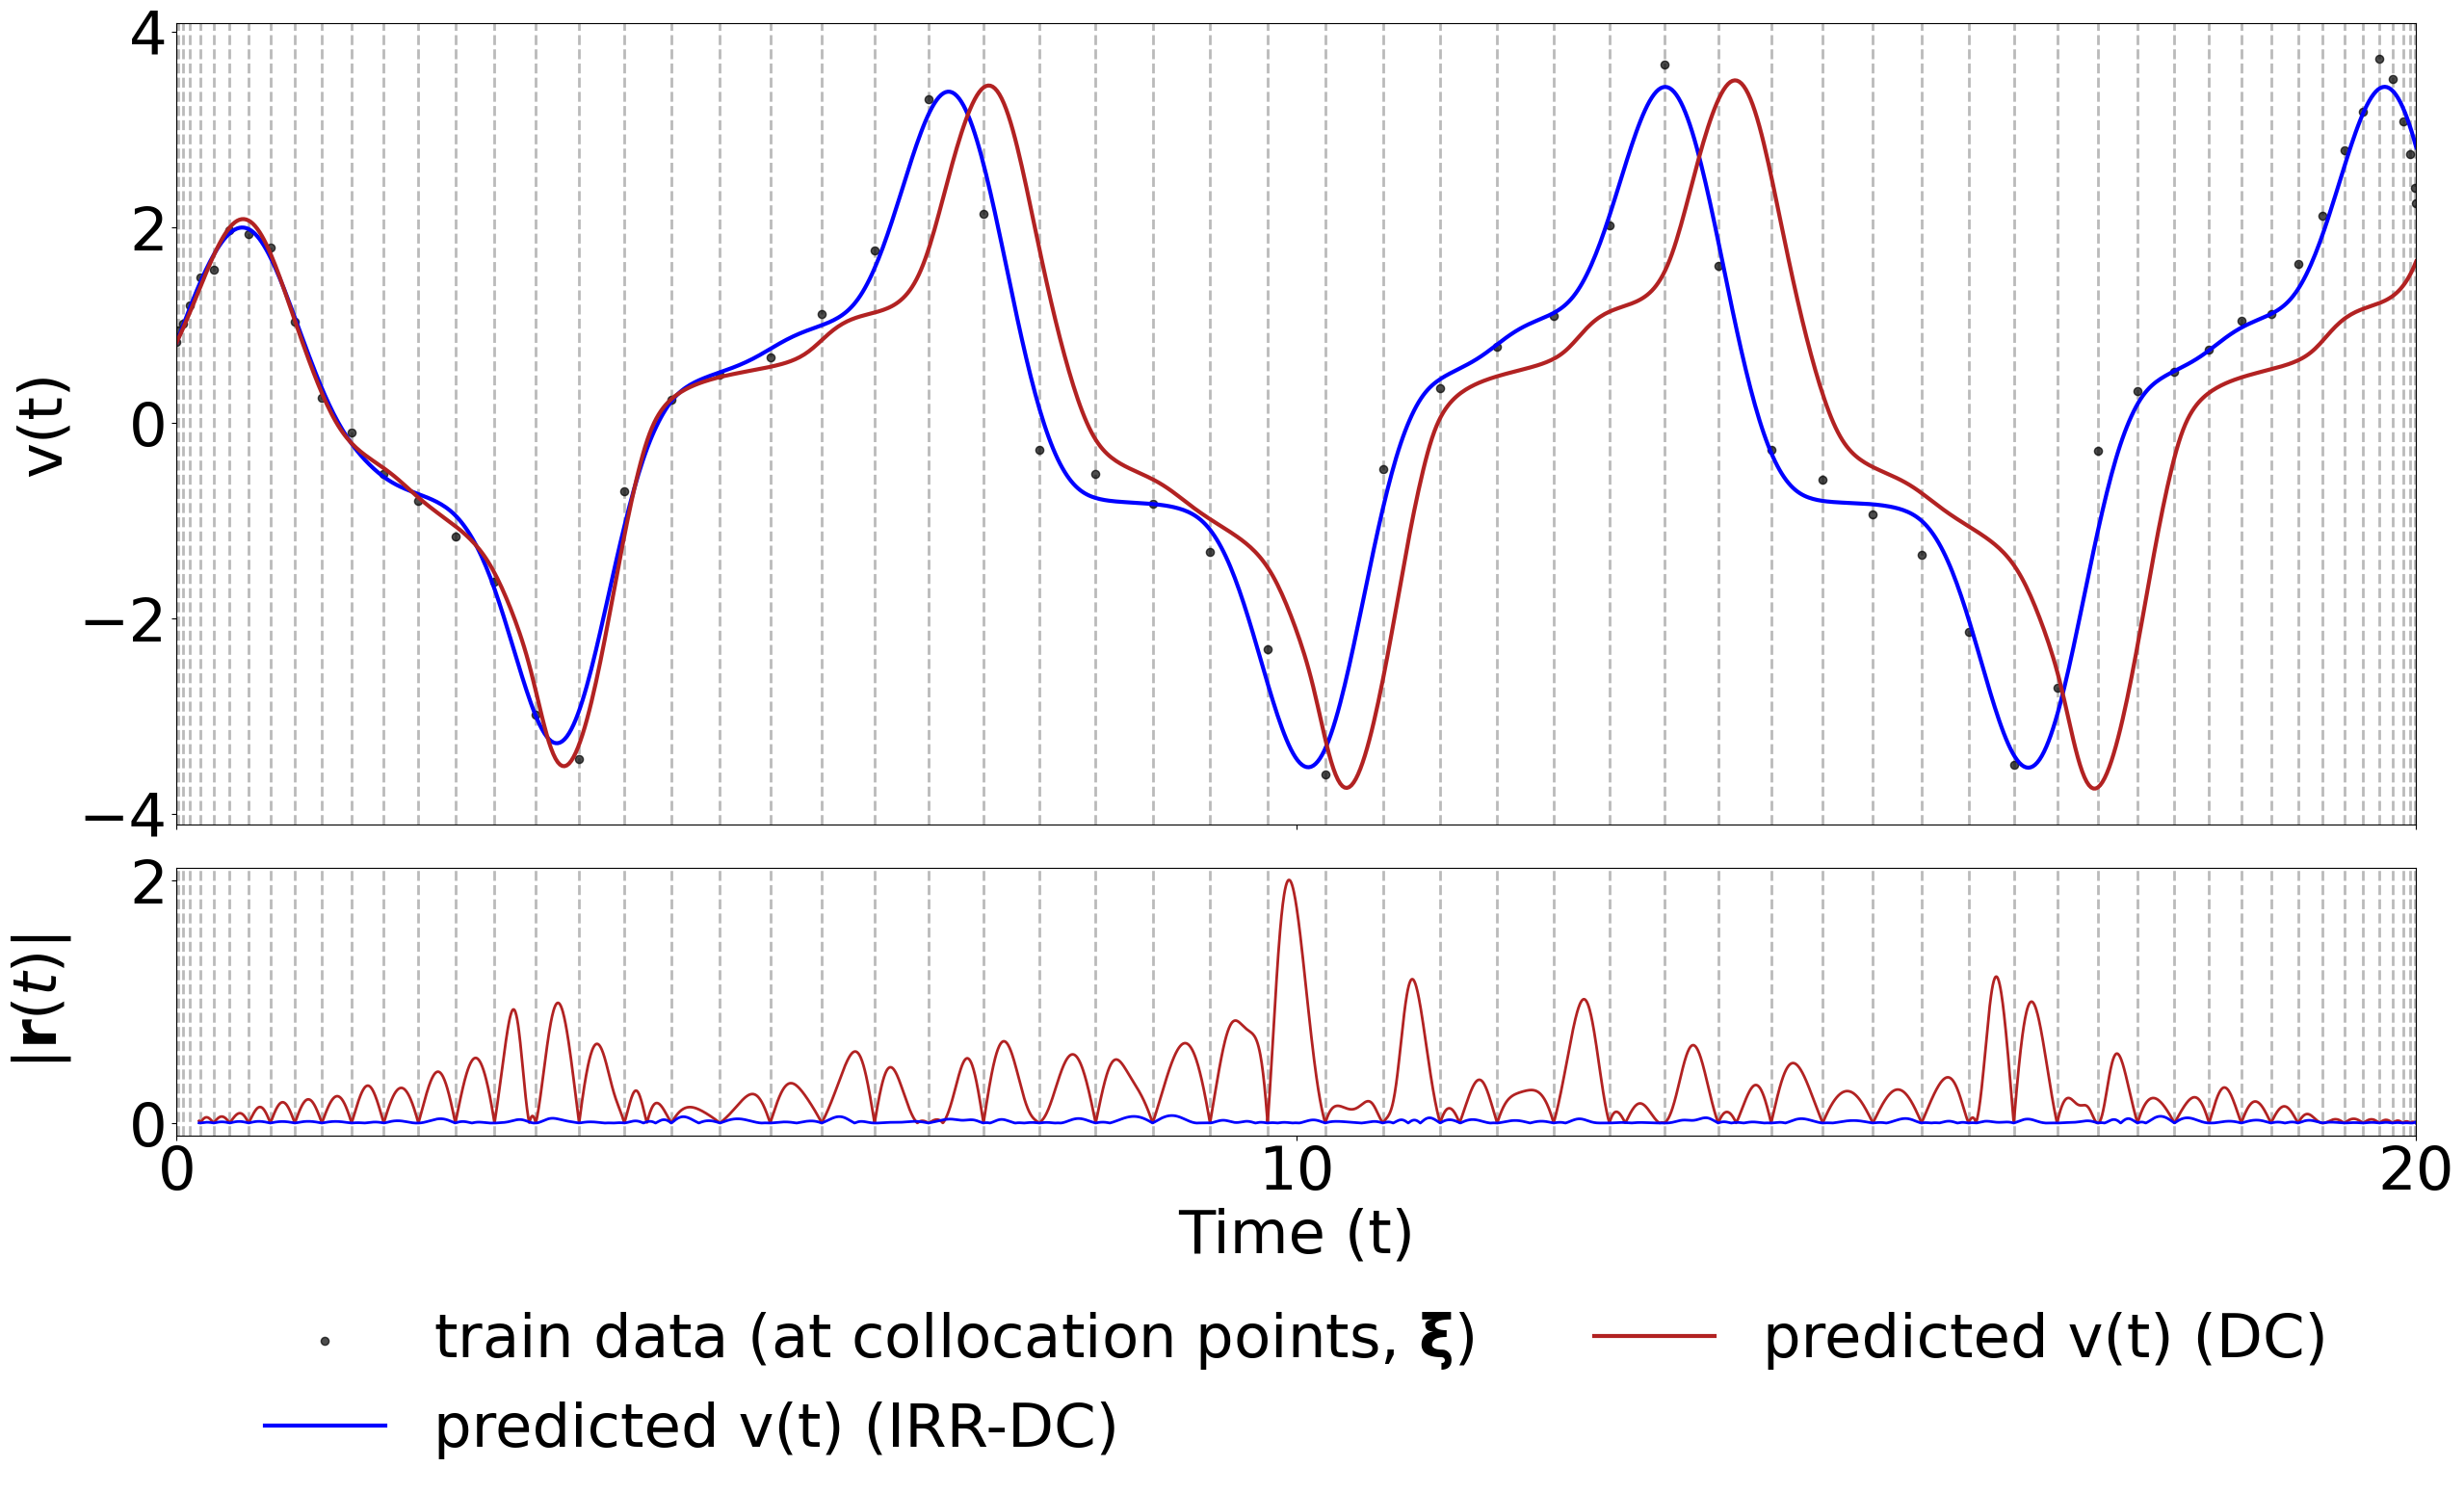

In [31]:
state_idx = 1  # velocity

fig, (ax_traj, ax_res) = plt.subplots(
    2, 1, sharex=True, figsize=(30, 15),
    gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.08}
)

tru_colour = (64/255, 64/255, 64/255)

# ---- top panel: predicted vs true trajectory ----
ax_traj.scatter(train_grid, Y_obs[:, state_idx], color='black', marker='o', s=35,
                alpha=0.7, label=r"train data (at collocation points, $\mathbf{\xi}$)")
ax_traj.plot(train_eval_grid, predicted_trajectory_train_irrdc[:, state_idx], color='blue', linewidth=3,
             label=r"predicted v(t) (IRR-DC)")
ax_traj.plot(train_eval_grid, predicted_trajectory_train_dc[:, state_idx], color='firebrick', linewidth=3,
             label=r"predicted v(t) (DC)")
ax_traj.set_ylabel(r"v(t)", fontsize=45)
ax_traj.set_yticks([-4, -2, 0, 2, 4])
ax_traj.tick_params(labelsize=45)
ax_traj.set_xlim(train_eval_grid[0], train_eval_grid[-1])

# ---- bottom panel: velocity ODE residual ----
ax_res.plot(t_plot_dc,    np.abs(res_plot_dc[:, state_idx]),    color='firebrick', linewidth=2,
            label="DC ($\rho=0$)")
ax_res.plot(t_plot_irrdc, np.abs(res_plot_irrdc[:, state_idx]), color='blue', linewidth=2,
            label=rf"IRR-DC ($\rho={pyo_model_irrdc.rho_reg}$)")
ax_res.set_ylabel(r"$|\mathbf{r}(t)|$", fontsize=45)
ax_res.set_xlabel("Time (t)", fontsize=45)
ax_res.set_xticks(np.arange(0, train_eval_grid[-1] + 1, 10))
ax_res.tick_params(labelsize=45)

# ---- vertical dashed lines at collocation nodes, linking both panels ----
for tc in train_grid:
    ax_traj.axvline(tc, color='darkgrey', linestyle='--', linewidth=2, alpha=0.8, zorder=0)
    ax_res.axvline(tc,  color='darkgrey', linestyle='--', linewidth=2, alpha=0.8, zorder=0)

# ---- shared legend below the time axis, 4 columns ----
handles, labels = ax_traj.get_legend_handles_labels()
ax_res.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.45),
              ncol=2, frameon=False, fontsize=45)

fig.align_ylabels([ax_traj, ax_res])